<a href="https://colab.research.google.com/github/Bless-O/human-mtbi-aperiodic-eeg/blob/main/03_cohort_lmm_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q mne mne-bids mne-icalabel specparam openneuro-py statsmodels seaborn
import os, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
from mne_bids import BIDSPath, read_raw_bids
from mne_icalabel import label_components
from specparam import SpectralGroupModel
import statsmodels.formula.api as smf
warnings.filterwarnings('ignore', category=RuntimeWarning)
mne.set_log_level('ERROR')

# 1. Pull metadata
!openneuro-py download \
    --dataset=ds005114 \
    --target-dir=/content/mtbi_data \
    --include=participants.tsv \
    --include=dataset_description.json

df_meta = pd.read_csv('/content/mtbi_data/participants.tsv', sep='\t')
df_meta['Group_Label'] = df_meta['Group'].map({0: 'mTBI', 1: 'Control'})

# 2. Pick balanced 10 mTBI + 10 Control mini-cohort
cohort = pd.concat([
    df_meta[df_meta['Group'] == 0].head(10),
    df_meta[df_meta['Group'] == 1].head(10)
]).reset_index(drop=True)

print(cohort[['participant_id', 'Group_Label', 'age', 'sex']])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.

👋 Hello! This is openneuro-py 2026.9.1. Great to see you! 🤗

   👉 Please report problems 🤯 and bugs 🪲 at
      https://github.com/openneuro-py/openneuro-py/issues

🌍 Preparing to download ds005114 …
📥 Checking 5 files, downloading as needed (5 concurrent downloads). 

Overall                  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0% 0.0/4.5 kB  ? -:--:--
Overall                  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0% 0.0/4.5 kB  ? -:--:--
dataset_description.json ━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0% 0/295 bytes ? -:--:--
Overall           ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   7% 0.3/4.5 kB  ? -:--:--
CHANGES           ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0% 0/36 bytes  ? 

## 2. Stream-Process-Clean Cohort Pipeline & Regional $1/f$ Extraction
This chunk iterates through the balanced 20-subject cohort (`ses-01`, `task-DPX`) using a low-disk-footprint stream-and-clean loop (downloading one subject at a time and removing raw `.fdt`/`.set` files immediately after feature extraction). For each subject, apply blink-proof bad-channel interpolation (15–100 Hz MAD z-score $> 5.0$), average referencing, and 30-component Extended Infomax ICA with `ICLabel` ($p > 0.65$). Fit `specparam` across both **2–40 Hz** and **2–30 Hz** (as a high-frequency EMG sensitivity check) and aggregate median exponents across interior **Frontal, Central, and Parietal** regions of interest (ROIs) to minimize peripheral muscle contamination before exporting `mtbi_cohort_exponents.csv`.

In [2]:
ROIS = {
    'Frontal':  ['F1', 'F2', 'F3', 'F4', 'Fz', 'FC1', 'FC2', 'FC3', 'FC4', 'FCz'],
    'Central':  ['C1', 'C2', 'C3', 'C4', 'Cz', 'CP1', 'CP2', 'CP3', 'CP4'],
    'Parietal': ['P1', 'P2', 'P3', 'P4', 'Pz', 'PO3', 'PO4', 'POz']
}

def extract_subject_rois(sub_id, root='/content/mtbi_data'):
    # Download ONLY ses-01 for this subject
    cmd = [
        'openneuro-py', 'download',
        '--dataset=ds005114',
        f'--target-dir={root}',
        f'--include={sub_id}/ses-01/*'
    ]
    subprocess.run(cmd, check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

    bids_path = BIDSPath(root=root, subject=sub_id.replace('sub-', ''), session='01', task='DPX', datatype='eeg')
    raw = read_raw_bids(bids_path, verbose=False)
    raw.load_data()

    # Fix channel types & montage
    ch_types = {
        ch: ('eog' if 'EOG' in ch.upper() else 'ecg' if ('EKG' in ch.upper() or 'ECG' in ch.upper()) else 'eeg')
        for ch in raw.ch_names
    }
    raw.set_channel_types(ch_types)
    raw.set_montage('colin27_1020', on_missing='ignore')
    raw_eeg = raw.copy().pick('eeg')

    # Filter 1-100 Hz
    raw_filt = raw_eeg.copy().filter(l_freq=1.0, h_freq=100.0, verbose=False)

    # Blink-proof bad-channel detection (15-100 Hz)
    raw_hf = raw_filt.copy().filter(l_freq=15.0, h_freq=None, verbose=False)
    ch_stds_hf = np.std(raw_hf.get_data(), axis=1)
    med = np.median(ch_stds_hf)
    mad = np.median(np.abs(ch_stds_hf - med)) * 1.4826
    robust_z = (ch_stds_hf - med) / (mad + 1e-12)
    ch_stds_full = np.std(raw_filt.get_data(), axis=1)

    bad_chs = [raw_filt.ch_names[i] for i in np.where((robust_z > 5.0) | (ch_stds_full < 1e-7))[0]]
    if bad_chs:
        raw_filt.info['bads'] = bad_chs
        raw_filt.interpolate_bads(reset_bads=True, verbose=False)

    # Average reference + ICA/ICLabel
    raw_filt.set_eeg_reference('average', projection=False, verbose=False)
    ica = mne.preprocessing.ICA(n_components=30, method='infomax', fit_params=dict(extended=True), random_state=42)
    ica.fit(raw_filt, verbose=False)

    ic_labels = label_components(raw_filt, ica, method='iclabel')
    exclude_idx = [
        i for i, (lbl, p) in enumerate(zip(ic_labels['labels'], ic_labels['y_pred_proba']))
        if lbl in ['eye blink', 'muscle artifact', 'channel noise'] and p > 0.65
    ]
    raw_clean = ica.apply(raw_filt.copy(), exclude=exclude_idx, verbose=False)

    # Compute Welch PSD once (2-40 Hz)
    psd = raw_clean.compute_psd(method='welch', fmin=2, fmax=40, n_fft=1024, verbose=False)
    freqs, spectra = psd.freqs, psd.get_data()

    # Fit specparam on BOTH 2-40 Hz and 2-30 Hz (for EMG sensitivity check)
    fg_40 = SpectralGroupModel(aperiodic_mode='fixed', peak_width_limits=[1, 12], max_n_peaks=6, verbose=False)
    fg_30 = SpectralGroupModel(aperiodic_mode='fixed', peak_width_limits=[1, 12], max_n_peaks=6, verbose=False)
    fg_40.fit(freqs, spectra, [2, 40])
    fg_30.fit(freqs, spectra, [2, 30])

    exp_40 = dict(zip(raw_clean.ch_names, fg_40.get_params('aperiodic', 'exponent')))
    exp_30 = dict(zip(raw_clean.ch_names, fg_30.get_params('aperiodic', 'exponent')))
    r2_40  = dict(zip(raw_clean.ch_names, fg_40.get_metrics('gof', 'rsquared')))

    rows = []
    for region, ch_list in ROIS.items():
        valid = [ch for ch in ch_list if ch in exp_40]
        rows.append({
            'participant_id': sub_id,
            'Region': region,
            'Exponent_2_40': np.nanmedian([exp_40[c] for c in valid]),
            'Exponent_2_30': np.nanmedian([exp_30[c] for c in valid]),
            'Median_R2':     np.nanmedian([r2_40[c] for c in valid]),
            'N_Bad_Chs':     len(bad_chs),
            'N_ICA_Excl':    len(exclude_idx)
        })

    # Clean up
    shutil.rmtree(os.path.join(root, sub_id), ignore_errors=True)
    return rows

# Run loop across all 20 subjects
all_rows = []
for idx, row in cohort.iterrows():
    sub_id = row['participant_id']
    try:
        sub_rows = extract_subject_rois(sub_id)
        all_rows.extend(sub_rows)
        print(f"[{idx+1}/{len(cohort)}] Done: {sub_id} ({row['Group_Label']})")
    except Exception as e:
        print(f"[{idx+1}/{len(cohort)}] SKIPPED {sub_id}: {e}")

df_res = pd.DataFrame(all_rows).merge(cohort[['participant_id', 'Group_Label', 'age', 'sex']], on='participant_id')
df_res.to_csv('/content/mtbi_cohort_exponents.csv', index=False)
print("\nSaved /content/mtbi_cohort_exponents.csv")
df_res.head(6)

[1/20] Done: sub-001 (mTBI)
[2/20] Done: sub-003 (mTBI)
[3/20] Done: sub-004 (mTBI)
[4/20] Done: sub-005 (mTBI)
[5/20] Done: sub-007 (mTBI)
[6/20] Done: sub-011 (mTBI)
[7/20] Done: sub-012 (mTBI)
[8/20] Done: sub-013 (mTBI)
[9/20] Done: sub-014 (mTBI)
[10/20] Done: sub-016 (mTBI)
[11/20] Done: sub-002 (Control)
[12/20] Done: sub-006 (Control)
[13/20] Done: sub-008 (Control)
[14/20] Done: sub-009 (Control)
[15/20] Done: sub-010 (Control)
[16/20] Done: sub-015 (Control)
[17/20] Done: sub-018 (Control)
[18/20] Done: sub-020 (Control)
[19/20] Done: sub-021 (Control)
[20/20] Done: sub-022 (Control)

Saved /content/mtbi_cohort_exponents.csv


,participant_id,Region,Exponent_2_40,Exponent_2_30,Median_R2,N_Bad_Chs,N_ICA_Excl,Group_Label,age,sex
0,sub-001,Frontal,1.002024,0.851303,0.990146,1,8,mTBI,23,1
1,sub-001,Central,1.442805,1.247194,0.989375,1,8,mTBI,23,1
2,sub-001,Parietal,1.347633,1.224220,0.993778,1,8,mTBI,23,1
3,sub-003,Frontal,1.650468,1.603333,0.992428,1,11,mTBI,19,0
4,sub-003,Central,1.297529,1.309000,0.995465,1,11,mTBI,19,0
5,sub-003,Parietal,1.696724,1.575658,0.998051,1,11,mTBI,19,0


In [3]:
# Model: Exponent ~ Group * Region + age + sex + (1 | participant_id)
# Reference levels: Control, Central
lmm_40 = smf.mixedlm(
    "Exponent_2_40 ~ C(Group_Label, Treatment('Control')) * C(Region) + age + sex",
    data=df_res,
    groups=df_res["participant_id"]
).fit()

print("=== LMM: 2–40 Hz Aperiodic Exponent ===")
print(lmm_40.summary())

# Quick sensitivity check on 2–30 Hz
lmm_30 = smf.mixedlm(
    "Exponent_2_30 ~ C(Group_Label, Treatment('Control')) * C(Region) + age + sex",
    data=df_res,
    groups=df_res["participant_id"]
).fit()

print("\n=== Sensitivity Check: 2–30 Hz Aperiodic Exponent ===")
print(lmm_30.summary().tables[1])

=== LMM: 2–40 Hz Aperiodic Exponent ===
                                    Mixed Linear Model Regression Results
Model:                              MixedLM                 Dependent Variable:                 Exponent_2_40
No. Observations:                   60                      Method:                             REML         
No. Groups:                         20                      Scale:                              0.0342       
Min. group size:                    3                       Log-Likelihood:                     -16.5546     
Max. group size:                    3                       Converged:                          Yes          
Mean group size:                    3.0                                                                      
-------------------------------------------------------------------------------------------------------------
                                                                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------

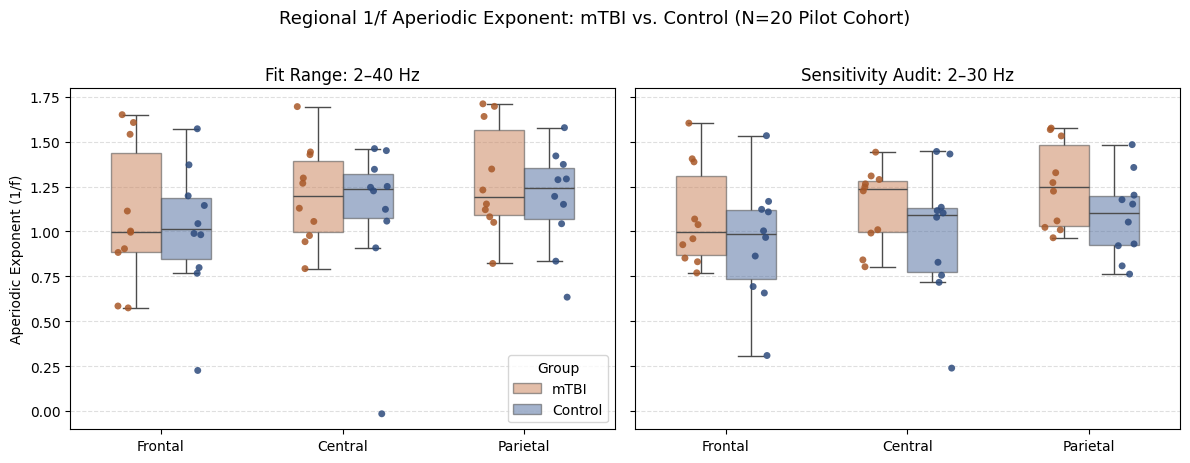

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, col, title in zip(
    axes,
    ['Exponent_2_40', 'Exponent_2_30'],
    ['Fit Range: 2–40 Hz', 'Sensitivity Audit: 2–30 Hz']
):
    sns.boxplot(
        data=df_res, x='Region', y=col, hue='Group_Label',
        palette={'Control': '#4C72B0', 'mTBI': '#DD8452'},
        width=0.55, showcaps=True, boxprops={'alpha': 0.55}, showfliers=False, ax=ax
    )
    sns.stripplot(
        data=df_res, x='Region', y=col, hue='Group_Label',
        palette={'Control': '#2c4a7c', 'mTBI': '#a85828'},
        dodge=True, alpha=0.85, size=5, legend=False, ax=ax
    )
    ax.set_title(title)
    ax.set_ylabel("Aperiodic Exponent (1/f)" if ax == axes[0] else "")
    ax.set_xlabel("")
    ax.grid(axis='y', ls='--', alpha=0.4)

axes[1].get_legend().remove()
axes[0].legend(title="Group", frameon=True)
plt.suptitle("Regional 1/f Aperiodic Exponent: mTBI vs. Control (N=20 Pilot Cohort)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('/content/fig3_cohort_lmm_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
df_qc = df_res[df_res['Median_R2'] >= 0.90].copy()
print(f"Retained {len(df_qc)}/{len(df_res)} ROI observations after R² >= 0.90 QC")

lmm_qc = smf.mixedlm(
    "Exponent_2_40 ~ C(Group_Label, Treatment('Control')) * C(Region) + age + sex",
    data=df_qc,
    groups=df_qc["participant_id"]
).fit()
print(lmm_qc.summary().tables[1])

Retained 55/60 ROI observations after R² >= 0.90 QC
                                                     Coef. Std.Err.       z  \
Intercept                                            1.168    0.249   4.689   
C(Group_Label, Treatment('Control'))[T.mTBI]         0.046    0.152   0.305   
C(Region)[T.Frontal]                                -0.134    0.076  -1.762   
C(Region)[T.Parietal]                               -0.006    0.076  -0.081   
C(Group_Label, Treatment('Control'))[T.mTBI]:C(...   0.100    0.110   0.911   
C(Group_Label, Treatment('Control'))[T.mTBI]:C(...   0.064    0.107   0.599   
age                                                  0.001    0.007   0.105   
sex                                                 -0.019    0.155  -0.120   
Group Var                                            0.061    0.198           

                                                    P>|z|  [0.025 0.975]  
Intercept                                           0.000   0.680  1.656  
C(Group